In [6]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError, CategoricalCrossentropy

import os
import random
from datetime import datetime
import time
import math


import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

In [3]:
import importlib
import DAE_DataGenerator
import dataset_utils
import SoftQuantizeLayer
import AnnealingScheduler

importlib.reload(DAE_DataGenerator)
importlib.reload(dataset_utils)
importlib.reload(SoftQuantizeLayer)
importlib.reload(AnnealingScheduler)

from DAE_DataGenerator import OptimizedDataGenerator
from dataset_utils import add_noise, quantize_manual
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *


2026-06-23 21:31:02.632436: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [1]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

# dataset_dir_train = os.path.join(dataset_base_dir, "/dataset_3sr_16x16_50x12P5_parquets", 'train/')
# dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')

# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748')

tfrecords_dir_train   = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856')



# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_80eN_raw')


print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [7]:
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    log_scale = False,
    select_contained = True,
    noise = -1, #[0,240],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds= [0, 30, 856],
    # charge_thresholds= [0, 7, 23, 134, 404, 867, 1748],
    bitwise_categorical = True,
    # charge_thresholds = None,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]

print("--- Validation generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:03<00:00,  5.52it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856 does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 21/21 [00:16<00:00,  1.27it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json
--- Validation generator 20.43426012992859 seconds ---


In [ ]:
print(validation_generator[0][0][28][:,:,1])
print(np.argmax(validation_generator[0][1][28], axis = -1)[:,:,1])

In [6]:
print(validation_generator.dataset_logmax, validation_generator.dataset_logmin)

16.239303966535875 -11.77206435145071


In [9]:
# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    log_scale = False,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = -1, #[0,240],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds= [0, 30, 856],
    # charge_thresholds = [0, 7, 23, 134, 404, 867, 1748],
    bitwise_categorical = True,
    # charge_thresholds = None,

    # threshold = 400,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

# training_generator = [training_generator[:][0], training_generator[:][0]]

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 80/80 [00:17<00:00,  4.47it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856 does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 84/84 [00:35<00:00,  2.36it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json
--- Training generator 53.85595965385437 seconds ---


In [4]:
#### Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json


2026-06-23 21:31:21.515652: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-06-23 21:31:21.551406: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-06-23 21:31:21.551727: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-06-23 21:31:21.552698: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

<class 'tensorflow.python.framework.ops.EagerTensor'>


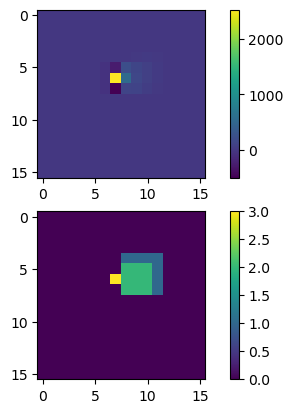

In [7]:

fig, ax = plt.subplots(2,1)
batch_index = 0
N = 12
ts = 0

# X_in = training_generator[batch_index][0][N]
# X_out = training_generator[batch_index][1][N]

X_in = validation_generator[batch_index][0][N]
X_out = validation_generator[batch_index][1][N]

# def get_min_max(training_generator, validation_generator):
#     tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
#     vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
#     return min(tmin, vmin), max(tmax, vmax)
# # print(training_generator.dataset_max, training_generator.dataset_min)
# # print(validation_generator.dataset_max, validation_generator.dataset_min)
# print(get_min_max(training_generator, validation_generator))
# print(training_generator[N][1].shape, training_generator[batch_index][1][N].dtype)
# # X_in = validation_generator[batch_index][0][N]
# X_out = validation_generator[batch_index][1][N]

a = ax[0].imshow(X_in[:,:,ts]) 
fig.colorbar(a)
a = ax[1].imshow(np.argmax(X_out[:,:,ts,], axis = -1)) 
# ax[2].imshow((X_in-X_out)[:,:,ts]) 
# print(X_in[:,:,ts])
print(type(X_in))
#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice
# ax[1].imshow(validation_generator[1][11][:,:,1])

fig.colorbar(a)


In [8]:
import models
importlib.reload(models)
# from models import CreateAutoEncoder
from SoftQuantizeLayer import SoftQuantizeLayer
from AnnealingScheduler import AnnealingScheduler

def encoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = QSeparableConv2D(
        n_filters, kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = QConv2D(
        n_filters,kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    return var

def decoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    # if input_quant is not None:
    #     # quantize = lambda x: quantize_manual(x, charge_levels = input_quant, quant_values =[0,1,2,3])
    #     quantize = lambda x: hard_quantize(x, levels = [0.0,1.0,2.0,3.0], thresholds = input_quant)
    #     var = Lambda(function=quantize, dtype=tf.float32)(var)
    return var

def Qdecoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Flatten()(var)
    var = Dense(math.prod(shape)*4, #activation='softmax'
               )(var)
    var = Reshape((*shape, 4))(var)
    return var

def get_min_max(training_generator, validation_generator, logrange=True):
    if logrange:
        tmax,tmin = [training_generator.dataset_logmax, training_generator.dataset_logmin]
        vmax,vmin = [validation_generator.dataset_logmax, validation_generator.dataset_logmin]
    else:
        tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
        vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
    return np.float32(min(tmin, vmin)), np.float32(max(tmax, vmax))

def CreateSQAutoEncoder(shape, n_filters=5, pool_size=2, conv_kernel_size=3, decoder_filters = 5, mean_filter=False, thresh = False, xrange = [-1,1], log_standardize=True):
    x_base = x_in = Input(shape)
    x_base = SoftQuantizeLayer(
        n_bits=2,
        # initial_thresholds = [247.80, 668.41, 1662.85],
        initial_thresholds = [10,240, 800],
        # initial_thresholds = [1,10, 30, 100, 400, 800, 1600],
        # initial_levels = [0.0, 0.33333, 0.66667, 1.0],
        initial_levels = [0.0, 1.0, 2.0, 3.0, #4.0, 5.0, 6.0, 7.0
                         ],
        threshold_offset = 0,
        # initial_range=[-1.0, 1.0],
        trainable_levels=False,
        trainable_thresholds=True,
        initial_k=1.0,
        trainable_k=False,
        name='soft_quantizer_output'
    )(x_base)
    stack = encoder_network(shape, x_base, n_filters=n_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    stack = Qdecoder_network(shape, stack, n_filters=decoder_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    # print(type(stack))
    if xrange is not None:
        def scaled_function(data):
            return asymmetric_scaling(data, pos_scale=xrange[1], neg_scale=abs(xrange[0]))
        stack = Lambda(function = scaled_function)(stack)
    model = Model(inputs=x_in, outputs=stack)
    return model

In [9]:
import loss
importlib.reload(loss)
from loss import CustomSSIMClass, CustomSSIM



model=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, 
                        # input_quant = [0.2,0.6,3.0],
                        xrange = None
                       )

#UNCOMMENT to Initialize from Weights
# weights_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_2bit_0eN_Target_0_30_856-checkpoints/'
# base_dir = weights_path
# checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
# best_weights = max(checkpoint_files, key=os.path.getmtime)
# print(f"Loading model from {best_weights}")
# model.load_weights(best_weights)


model.compile(
    # optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3, clipnorm=1.0),
    # loss=MeanSquaredError()
    # loss=CustomSSIMClass(xrange = xrange, log_standardize = False),
    # loss=CustomSSIM(logxrange = xrange, 
    #                 log_standardize = True)
    loss = CategoricalCrossentropy(reduction = 'sum', from_logits=True)
    # run_eagerly=True
)

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d (QSepara  (None, 16, 16, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 16, 16, 5)         0         
                                                                 
 average_pooling2d (AverageP  (None, 8, 8, 5)          0         
 ooling2D)                                                       
                                                             

In [10]:
from datetime import datetime
tname = 'SQDAE_Categorical_2bit_0eN_Target_0_30_856'#0_7_23_134_404_867_1748'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.4f}-v{val_loss:.4f}.hdf5'
print("fingerprint: ", fingerprint)

fingerprint:  65492abf


In [11]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback
import csv

early_stopping_patience = 500

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

class SoftQuantizeLoggerCallback(Callback):
    def __init__(self, log_filepath, layer_name="soft_quantizer_output"):
        super().__init__()
        self.log_filepath = log_filepath
        self.layer_name = layer_name
        self.header_written = False

    def on_train_begin(self, logs=None):
        os.makedirs(os.path.dirname(self.log_filepath), exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        try:
            layer = self.model.get_layer(self.layer_name)
            if not hasattr(layer, 'n_bits'):
                 print(f"\nWarning: Layer '{self.layer_name}' is not a SoftQuantizeLayer. Skipping logging.")
                 return
        except ValueError:
            print(f"\nWarning: Layer '{self.layer_name}' not found in the model. Skipping logging.")
            return

        if not self.header_written:
            num_levels = layer.num_levels
            num_thresholds = num_levels - 1
            
            header = ['epoch', 'k']
            header.extend([f'level_{i}' for i in range(num_levels)])
            header.extend([f'threshold_{i}' for i in range(num_thresholds)])

            header.append('raw_first_level')
            header.extend([f'raw_log_level_delta_{i}' for i in range(num_levels - 1)])
            header.append('raw_first_threshold')
            if hasattr(layer, 'log_threshold_deltas'):
                header.extend([f'raw_log_threshold_delta_{i}' for i in range(num_thresholds - 1)])

            with open(self.log_filepath, mode='w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(header)
            self.header_written = True

        k_val = layer.k.numpy().item()
        levels = layer.levels.numpy().tolist()
        thresholds = layer.thresholds.numpy().tolist()
        
        # first_level = layer.first_level.numpy().item()
        # log_level_deltas = layer.log_level_deltas.numpy().tolist()
        # first_threshold = layer.first_threshold.numpy().item()
        
        row_data = [epoch, k_val]
        row_data.extend(levels)
        row_data.extend(thresholds)
        # row_data.append(first_level)
        # row_data.extend(log_level_deltas)
        # row_data.append(first_threshold)
        
        if hasattr(layer, 'log_threshold_deltas'):
            log_threshold_deltas = layer.log_threshold_deltas.numpy().tolist()
            row_data.extend(log_threshold_deltas)
        
        with open(self.log_filepath, mode='a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(row_data)


csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)
scheduler_callback = AnnealingScheduler(
    schedule='cosine',  
    target_layer_name='soft_quantizer_output', 
    initial_k=1.0,
    final_k=200.0, 
    verbose=1      
)

quantizer_logger = SoftQuantizeLoggerCallback(
    log_filepath=f"{base_dir}/soft_quantizer_state_log.csv", # New, more descriptive filename
    layer_name="soft_quantizer_output"
)

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)


In [12]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger,scheduler_callback, quantizer_logger],
        epochs=2000,
        shuffle=False,
        verbose=1
    )


Epoch 1: Annealing 'k' set to 1.0000
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 10.0000, 240.0000, 800.0001
	Tau: [120.000015 395.00003  560.00006 ]
Epoch 1/2000


2026-06-23 21:31:57.294261: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-06-23 21:31:57.306944: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


84/84 [==============================] - ETA: 0s - loss: 904786.3125
Epoch 1: val_loss improved from inf to 423316.03125, saving model to ./SQ_DAE/model-65492abf-SQDAE_Categorical_2bit_0eN_Target_0_30_856-checkpoints/weights.01-t904786.3125-v423316.0312.hdf5
84/84 [==============================] - 83s 856ms/step - loss: 904786.3125 - val_loss: 423316.0312

Epoch 2: Annealing 'k' set to 1.0001
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 10.2430, 244.6861, 816.0522
	Tau: [122.34307 402.9046  571.366  ]
Epoch 2/2000
84/84 [==============================] - ETA: 0s - loss: 377924.9375
Epoch 2: val_loss improved from 423316.03125 to 340202.50000, saving model to ./SQ_DAE/model-65492abf-SQDAE_Categorical_2bit_0eN_Target_0_30_856-checkpoints/weights.02-t377924.9375-v340202.5000.hdf5
84/84 [==============================] - 20s 236ms/step - loss: 377924.9375 - val_loss: 340202.5000

Epoch 3: Annealing 'k' set to 1.0005
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 10.2170, 243

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [ ]:
'''Load weights and extract the encoder'''

import models
importlib.reload(models)
from models import CreateAutoEncoder

weights_path = './trained_models/DAE/model-e4177e22-DAE_80eNoise_5filters_convTranspose-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")
DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3)
DAE.load_weights(latest_checkpoint)
model_summary = [[layer.name, layer.output.shape] for layer in DAE.layers]

# for layer in DAE.layers:
#     print(layer.name)

layer_name = DAE.layers[8].name 
# print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
encoder.summary()

print(encoder.output.shape)



In [ ]:
'''attach a dense regression network to the latent space'''
from models import var_network

x_in = encoder.input
lat_shape = encoder.output.shape
dense = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense)

model.summary()